# SW05

In [7]:
import numpy as np
import scipy.integrate as integrate
import matplotlib.pyplot as plt

## Aufgabe 1.3 a)

$$y(t_i) = \int_{-1}^{1} \frac{-s}{1 + (s - t_i)^2} \, ds$$

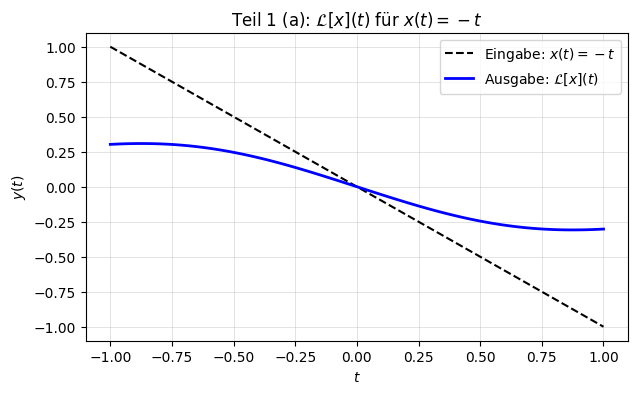

In [8]:
t_vals = np.linspace(-1, 1, 100)
y_vals = []
for t in t_vals:
    result, _ = integrate.quad(lambda s: -s / (1 + (s - t)**2), -1, 1)
    y_vals.append(result)

plt.figure(figsize=(7, 4))
plt.plot(t_vals, -t_vals, 'k--', label='Eingabe: $x(t) = -t$')
plt.plot(t_vals, y_vals, 'b-', lw=2, label='Ausgabe: $\mathcal{L}[x](t)$')
plt.title('Teil 1 (a): $\mathcal{L}[x](t)$ für $x(t) = -t$')
plt.xlabel('$t$')
plt.ylabel('$y(t)$')
plt.grid(True)
plt.legend()
plt.show()

## Aufgabe 1.3 b)

$$y(t_i) = \int_{-1}^{1} \frac{|s|}{1 + (s - t_i)^2} \, ds$$

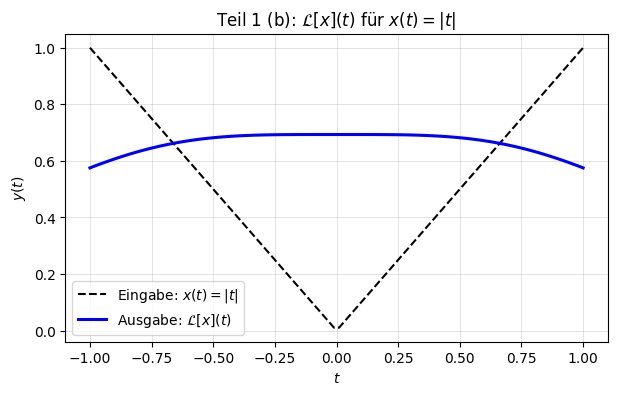

In [9]:
t_vals = np.linspace(-1, 1, 100)
y_vals = []
for t in t_vals:
    result, _ = integrate.quad(lambda s: np.abs(s) / (1 + (s - t)**2), -1, 1)
    y_vals.append(result)

plt.figure(figsize=(7, 4))
plt.plot(t_vals, np.abs(t_vals), 'k--', label=r'Eingabe: $x(t) = |t|$')
plt.plot(t_vals, y_vals, 'b-', lw=2.2, label=r'Ausgabe: $\mathcal{L}[x](t)$')
plt.title(r'Teil 1 (b): $\mathcal{L}[x](t)$ für $x(t) = |t|$')
plt.xlabel('$t$')
plt.ylabel('$y(t)$')
plt.grid(True)
plt.legend()
plt.show()

## Aufgabe 1.4.2

(np.float64(-0.5), np.float64(511.5), np.float64(511.5), np.float64(-0.5))

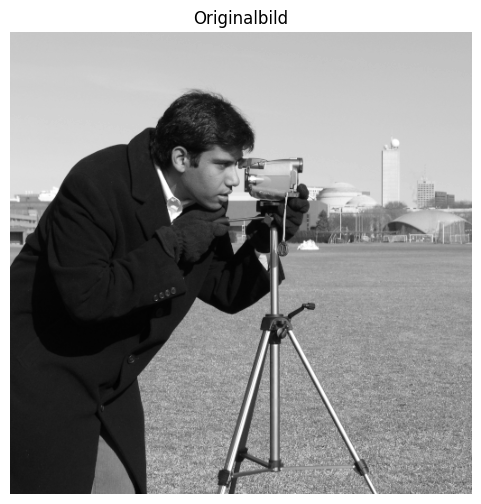

In [17]:
from scipy.signal import convolve2d
from skimage import data

# Klassisches Testbild "camera" (Graustufen, 512x512)
image = data.camera()

# show image
plt.figure(figsize=(6, 6))
plt.imshow(image, cmap='gray')
plt.title('Originalbild')
plt.axis('off')

(np.float64(-0.5), np.float64(511.5), np.float64(511.5), np.float64(-0.5))

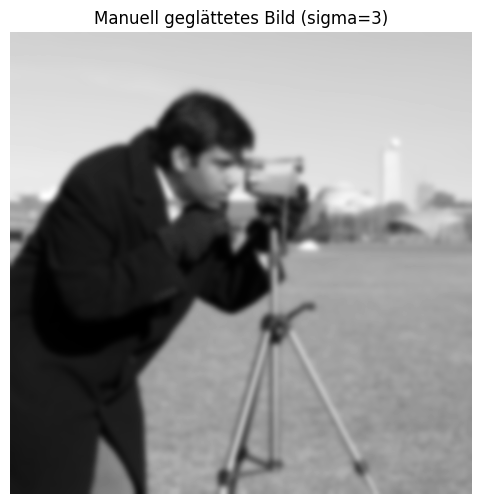

In [19]:
def make_gaussian_kernel(sigma, radius=None):
    if radius is None:
        radius = int(np.ceil(3 * sigma))

    # 1D-Koordinatengitter
    coords = np.arange(-radius, radius + 1)
    x, y = np.meshgrid(coords, coords)

    # 2D-Gauß-Glocke berechnen
    kernel = np.exp(-(x**2 + y**2) / (2 * sigma**2))

    # Normierung, damit die Gesamthelligkeit erhalten bleibt
    kernel /= kernel.sum()
    return kernel

# Kernel für sigma = 3 erstellen und anwenden
kernel = make_gaussian_kernel(sigma=3.0)
blurred_manual = convolve2d(image, kernel, mode='same', boundary='symm')

# show blurred image
plt.figure(figsize=(6, 6))
plt.imshow(blurred_manual, cmap='gray')
plt.title('Manuell geglättetes Bild (sigma=3)')
plt.axis('off')

## Test der Box-Filter (Harter Kernel) im Vergleich zum Gauß-Filter

(np.float64(-0.5), np.float64(511.5), np.float64(511.5), np.float64(-0.5))

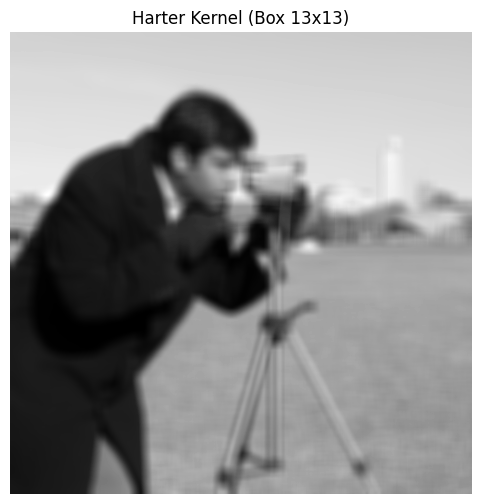

In [22]:
# 1. Bild laden und normalisieren
image = data.camera().astype(np.float64) / 255.0

# 2. Gauß-Kernel definieren
def make_gaussian_kernel(sigma):
    radius = int(np.ceil(3 * sigma))
    coords = np.arange(-radius, radius + 1)
    x, y = np.meshgrid(coords, coords)
    kernel = np.exp(-(x**2 + y**2) / (2.0 * sigma**2))
    return kernel / kernel.sum()

# 3. Harter Kernel (Box-Filter / Gleichverteilung)
def make_box_kernel(size):
    # Alle Gewichte sind identisch: 1 / (size * size)
    kernel = np.ones((size, size), dtype=np.float64)
    return kernel / kernel.sum()

# Parameter für vergleichbare Fenstergrößen
sigma = 2.0
kernel_gauss = make_gaussian_kernel(sigma=sigma)

# Kernel-Größe des Gauß-Filters: 2 * ceil(3*sigma) + 1
box_size = kernel_gauss.shape[0]  # Gleiche Fenstergröße (z. B. 13x13)
kernel_box = make_box_kernel(size=box_size)

# 4. Faltungen durchführen
blurred_gauss = convolve2d(image, kernel_gauss, mode='same', boundary='symm')
blurred_box = convolve2d(image, kernel_box, mode='same', boundary='symm')

# show blurred image
plt.figure(figsize=(6, 6))
plt.imshow(blurred_box, cmap='gray')
plt.title(f'Harter Kernel (Box {box_size}x{box_size})')
plt.axis('off')


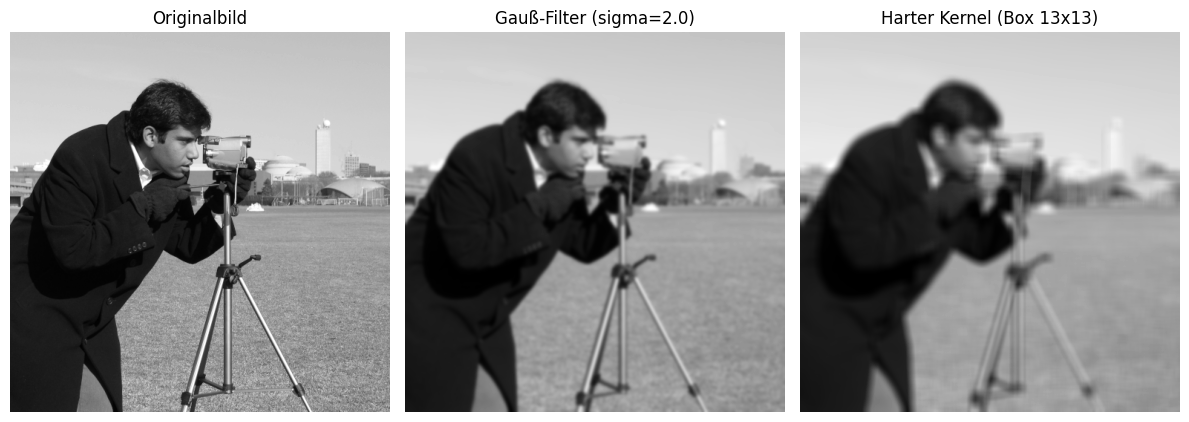

In [26]:
# side by side comparison (Original, Gaussian, Box)
plt.figure(figsize=(12, 6))
plt.subplot(1, 3, 1)
plt.imshow(image, cmap='gray')
plt.title('Originalbild')
plt.axis('off')
plt.subplot(1, 3, 2)
plt.imshow(blurred_gauss, cmap='gray')
plt.title(f'Gauß-Filter (sigma={sigma})')
plt.axis('off')
plt.subplot(1, 3, 3)
plt.imshow(blurred_box, cmap='gray')
plt.title(f'Harter Kernel (Box {box_size}x{box_size})')
plt.axis('off')
plt.tight_layout()
plt.show()